# How students really fill in course evaluations

Universities use end-of-term questionnaires to compare courses and instructors. This notebook looks at 5,820 evaluations from Gazi University in Ankara, each with 28 questions answered on a scale from 1 (strongly disagree) to 5 (strongly agree). Questions 1 to 12 are about the course and questions 13 to 28 are about the instructor.

The starting question was which aspects of teaching students rate highest. The data pushed towards a different one: **how much of an evaluation score reflects the teaching, and how much reflects the way a student fills in the form?**

1. A first look
2. Straight-lining: one answer for all 28 questions
3. Who straight-lines?
4. What is left once straight-liners are set aside
5. Does it change how instructors compare?

Data: the Turkiye Student Evaluation dataset from the UCI Machine Learning Repository.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid")

evals = pd.read_csv("data/turkiye-student-evaluation_generic.csv").rename(columns={"nb.repeat": "repeats"})
questions = [f"Q{i}" for i in range(1, 29)]
course_q, instructor_q = questions[:12], questions[12:]

print(evals.shape, "| missing values:", int(evals.isna().sum().sum()))
evals.head()

(5820, 33) | missing values: 0


,instr,class,repeats,attendance,difficulty,Q1,Q2,Q3,Q4,Q5,...,Q19,Q20,Q21,Q22,Q23,Q24,Q25,Q26,Q27,Q28
0,1,2,1,0,4,3,3,3,3,3,...,3,3,3,3,3,3,3,3,3,3
1,1,2,1,1,3,3,3,3,3,3,...,3,3,3,3,3,3,3,3,3,3
2,1,2,1,2,4,5,5,5,5,5,...,5,5,5,5,5,5,5,5,5,5
3,1,2,1,1,3,3,3,3,3,3,...,3,3,3,3,3,3,3,3,3,3
4,1,2,1,0,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1


Besides the 28 answers, each row has the instructor (3 instructors), the course (13 courses), how many times the student has taken the course, their attendance level (0 to 4) and how difficult they found the course (1 to 5).

## 1. A first look

The average answer to each question:

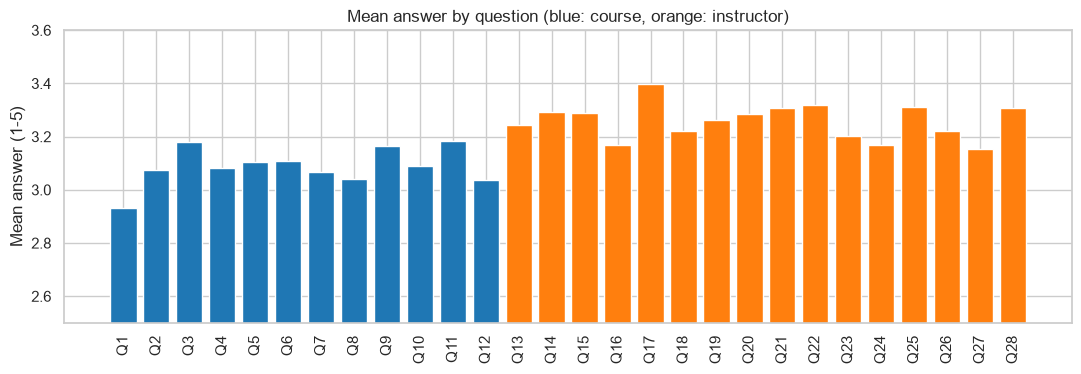

Course questions: mean 3.09 | instructor questions: mean 3.26
Lowest: Q1 (2.93) | highest: Q17 (3.40)


In [2]:
means = evals[questions].mean()

fig, ax = plt.subplots(figsize=(13, 3.8))
ax.bar(questions, means, color=["tab:blue"] * 12 + ["tab:orange"] * 16)
ax.set_ylim(2.5, 3.6)
ax.set_ylabel("Mean answer (1-5)")
ax.set_title("Mean answer by question (blue: course, orange: instructor)")
plt.xticks(rotation=90)
plt.show()

print(f"Course questions: mean {evals[course_q].mean().mean():.2f} | instructor questions: mean {evals[instructor_q].mean().mean():.2f}")
print(f"Lowest: {means.idxmin()} ({means.min():.2f}) | highest: {means.idxmax()} ({means.max():.2f})")

Every question averages close to 3, and the answers to different questions are almost interchangeable:

Correlation between pairs of questions: median 0.81, lowest 0.61


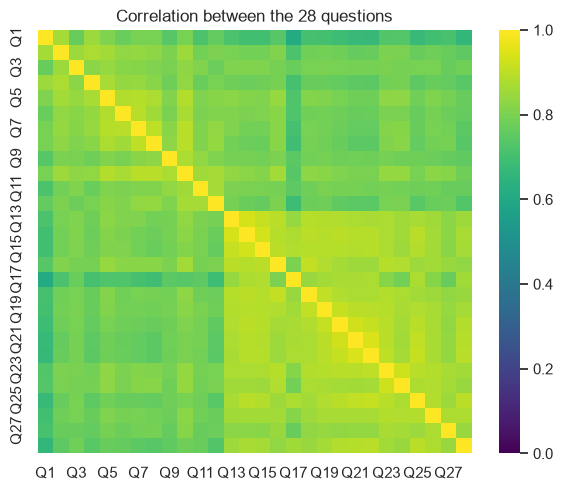

In [3]:
corr = evals[questions].corr()
off_diagonal = corr.values[np.triu_indices(28, k=1)]
print(f"Correlation between pairs of questions: median {np.median(off_diagonal):.2f}, lowest {off_diagonal.min():.2f}")

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, vmin=0, vmax=1, cmap="viridis", ax=ax)
ax.set_title("Correlation between the 28 questions")
plt.show()

Twenty-eight questions about different things should not all agree this closely. Something about how the form is filled in is producing the pattern.

## 2. Straight-lining

A straight-liner gives the same answer to every question. It is the quickest way through a compulsory form.

Straight-liners: 2,985 of 5,820 (51.3%)
Used only two different answers: 15.0%


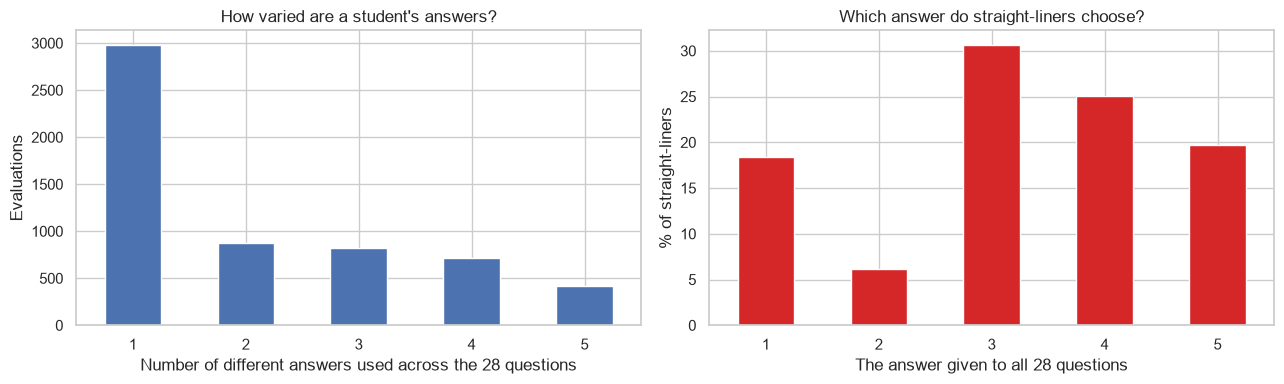

Q1,1,2,3,4,5
% of straight-liners,18.4,6.2,30.7,25.0,19.7


In [4]:
evals["distinct_answers"] = evals[questions].nunique(axis=1)
evals["straight"] = evals["distinct_answers"] == 1
evals["mean_score"] = evals[questions].mean(axis=1)

print(f"Straight-liners: {evals['straight'].sum():,} of {len(evals):,} ({evals['straight'].mean():.1%})")
print(f"Used only two different answers: {(evals['distinct_answers'] == 2).mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
evals["distinct_answers"].value_counts().sort_index().plot.bar(ax=axes[0], rot=0)
axes[0].set_xlabel("Number of different answers used across the 28 questions")
axes[0].set_ylabel("Evaluations")
axes[0].set_title("How varied are a student's answers?")

which = evals.loc[evals["straight"], "Q1"].value_counts(normalize=True).sort_index() * 100
which.plot.bar(ax=axes[1], rot=0, color="tab:red")
axes[1].set_xlabel("The answer given to all 28 questions")
axes[1].set_ylabel("% of straight-liners")
axes[1].set_title("Which answer do straight-liners choose?")
plt.tight_layout()
plt.show()
which.round(1).to_frame("% of straight-liners").T

Could that many identical forms arise by chance? If students answered each question independently, with the same overall mix of answers, the chance of 28 identical answers would be:

In [5]:
answer_shares = evals[questions].stack().value_counts(normalize=True)
chance = (answer_shares ** 28).sum()
print(f"Probability of an all-identical form under independent answers: {chance:.1e}")
print(f"Expected number among {len(evals):,} forms: {chance * len(evals):.1e}  (observed: {evals['straight'].sum():,})")

Probability of an all-identical form under independent answers: 8.2e-16
Expected number among 5,820 forms: 4.8e-12  (observed: 2,985)


## 3. Who straight-lines?

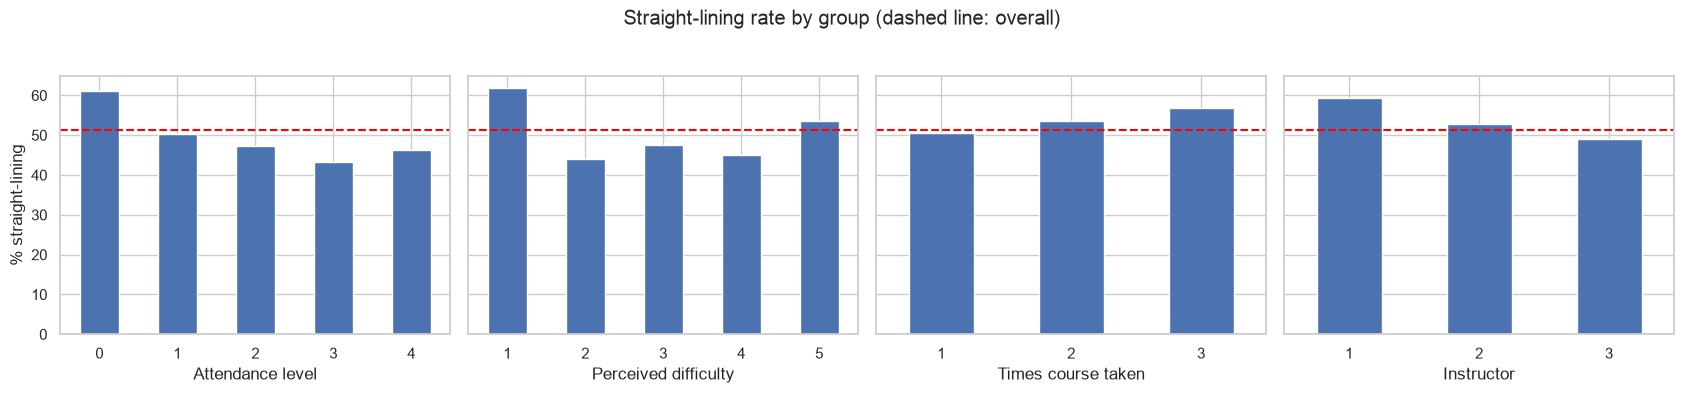

attendance  rate by level: {0: 61, 1: 50, 2: 47, 3: 43, 4: 46}  (chi-square p = 1.3e-24)
difficulty  rate by level: {1: 62, 2: 44, 3: 47, 4: 45, 5: 54}  (chi-square p = 1.3e-23)
repeats     rate by level: {1: 51, 2: 54, 3: 57}  (chi-square p = 4.8e-02)
instr       rate by level: {1: 59, 2: 53, 3: 49}  (chi-square p = 6.6e-07)


In [6]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8), sharey=True)
for ax, column, label in zip(axes, ["attendance", "difficulty", "repeats", "instr"],
                             ["Attendance level", "Perceived difficulty", "Times course taken", "Instructor"]):
    rate = evals.groupby(column)["straight"].mean() * 100
    rate.plot.bar(ax=ax, rot=0)
    ax.set_xlabel(label)
    ax.axhline(evals["straight"].mean() * 100, color="red", linestyle="--")
axes[0].set_ylabel("% straight-lining")
fig.suptitle("Straight-lining rate by group (dashed line: overall)", y=1.03)
plt.tight_layout()
plt.show()

for column in ["attendance", "difficulty", "repeats", "instr"]:
    table = pd.crosstab(evals[column], evals["straight"])
    chi2, p, _, _ = stats.chi2_contingency(table)
    rate = (evals.groupby(column)["straight"].mean() * 100).round(0).astype(int).to_dict()
    print(f"{column:<11} rate by level: {rate}  (chi-square p = {p:.1e})")

In [7]:
by_course = evals.groupby("class").agg(evaluations=("straight", "size"), straight_pct=("straight", lambda s: s.mean() * 100))
by_course.sort_values("straight_pct").round(1).T

class,8,4,5,7,9,13,11,6,1,3,12,10,2
evaluations,500.0,187.0,656.0,187.0,571.0,841.0,484.0,558.0,303.0,904.0,41.0,448.0,140.0
straight_pct,33.8,36.4,45.0,46.0,49.2,52.3,53.3,53.4,55.1,58.2,58.5,61.6,69.3


## 4. What is left without the straight-liners

With straight-liners in, a single component explains almost all the variation in the answers. The same analysis on the remaining students shows how much structure the questionnaire really has.

In [8]:
varied = evals[~evals["straight"]]


def explained(data, n=3):
    return PCA(n_components=n).fit(data[questions] - data[questions].mean()).explained_variance_ratio_ * 100


pca_table = pd.DataFrame({"all evaluations": explained(evals), "straight-liners removed": explained(varied)},
                         index=["component 1", "component 2", "component 3"]).round(1)
display(pca_table)

corr_varied = varied[questions].corr()
within_course = corr_varied.loc[course_q, course_q].values[np.triu_indices(12, k=1)].mean()
within_instructor = corr_varied.loc[instructor_q, instructor_q].values[np.triu_indices(16, k=1)].mean()
between = corr_varied.loc[course_q, instructor_q].values.mean()
print(f"Mean correlation among varied responders: within course questions {within_course:.2f}, "
      f"within instructor questions {within_instructor:.2f}, between the two blocks {between:.2f}")

,all evaluations,straight-liners removed
component 1,82.2,60.5
component 2,4.5,8.9
component 3,1.5,3.4


Mean correlation among varied responders: within course questions 0.61, within instructor questions 0.71, between the two blocks 0.51


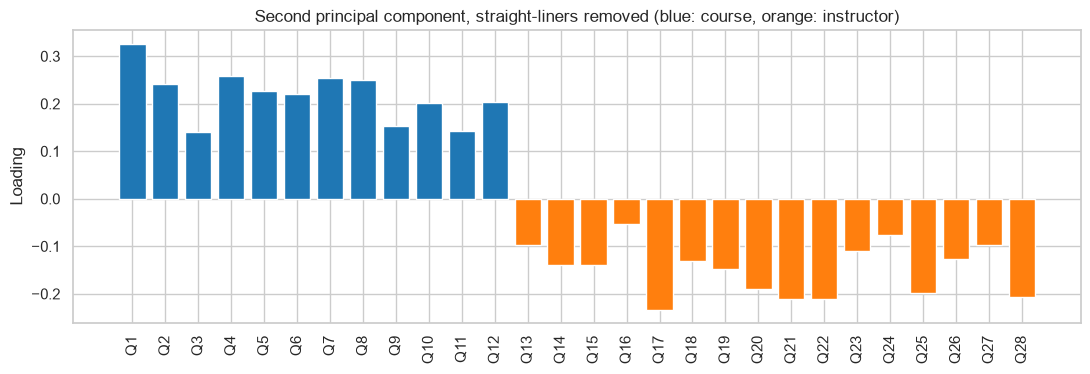

In [9]:
pca = PCA(n_components=2).fit(varied[questions] - varied[questions].mean())
loadings = pd.DataFrame(pca.components_.T, index=questions, columns=["component 1", "component 2"])

fig, ax = plt.subplots(figsize=(13, 3.8))
ax.bar(questions, loadings["component 2"], color=["tab:blue"] * 12 + ["tab:orange"] * 16)
ax.set_title("Second principal component, straight-liners removed (blue: course, orange: instructor)")
ax.set_ylabel("Loading")
plt.xticks(rotation=90)
plt.show()

## 5. Does it change how instructors and courses compare?

The usual report is a mean score per instructor or per course. Here it is computed three ways: from everyone, from straight-liners only, and from the students who varied their answers.

In [10]:
def summary(column):
    return pd.DataFrame({
        "evaluations": evals.groupby(column).size(),
        "straight %": (evals.groupby(column)["straight"].mean() * 100).round(0),
        "mean (all)": evals.groupby(column)["mean_score"].mean(),
        "mean (straight-liners)": evals[evals["straight"]].groupby(column)["mean_score"].mean(),
        "mean (varied)": varied.groupby(column)["mean_score"].mean(),
    }).round(2)


summary("instr")

,evaluations,straight %,mean (all),mean (straight-liners),mean (varied)
instr,,,,,
1,775,59.0,3.38,3.43,3.30
2,1444,53.0,3.39,3.41,3.37
3,3601,49.0,3.06,3.07,3.05


In [11]:
courses = summary("class")
courses["rank (all)"] = courses["mean (all)"].rank(ascending=False).astype(int)
courses["rank (varied)"] = courses["mean (varied)"].rank(ascending=False).astype(int)
courses["rank change"] = courses["rank (all)"] - courses["rank (varied)"]
rho, _ = stats.spearmanr(courses["mean (all)"], courses["mean (varied)"])
print(f"Rank correlation between the two course rankings: {rho:.2f}")
courses.sort_values("rank (all)")

Rank correlation between the two course rankings: 0.74


,evaluations,straight %,mean (all),mean (straight-liners),mean (varied),rank (all),rank (varied),rank change
class,,,,,,,,
2,140,69.0,3.59,3.67,3.42,1,1,0
1,303,55.0,3.44,3.47,3.40,2,3,-1
10,448,62.0,3.44,3.53,3.29,2,6,-4
6,558,53.0,3.40,3.39,3.41,4,2,2
11,484,53.0,3.37,3.42,3.30,5,5,0
8,500,34.0,3.28,3.40,3.22,6,8,-2
5,656,45.0,3.20,3.33,3.09,7,10,-3
9,571,49.0,3.17,3.17,3.17,8,9,-1
7,187,46.0,3.07,2.85,3.27,9,7,2


## Findings

- **Half the forms carry one number.** 51% of students gave the same answer to all 28 questions, and another 15% used only two different answers. Under independent answering an all-identical form would essentially never occur.
- **Straight-liners do not all pick the middle.** 31% chose 3 throughout, but 25% chose 4, 20% chose 5 and 18% chose 1. Many are expressing one overall verdict on the course.
- **Who does it:** students who never attend (61%, against 43-50% for the rest) and students who found the course very easy (62%) or very hard (54%). The rate by course runs from 34% to 69%.
- **The questionnaire's structure only shows without them.** With everyone included, one component explains 82% of the variation and the 28 questions look like one question asked 28 times. Among students who varied their answers that falls to 60%, and the second component cleanly separates the course questions from the instructor questions.
- **Instructor comparisons survive.** Instructor 3 scores about 0.3 lower than the other two whichever group is used.
- **Course rankings are less stable.** The rank correlation between "all students" and "varied responders" is 0.74. One small course moves from 11th of 13 to 4th, and another from 3rd to 6th.

**What to take from it:** a mean evaluation score is mostly a measure of overall sentiment, and for small courses it depends heavily on who rushed the form. Reporting the straight-lining rate next to each score, and checking whether a ranking holds among varied responders, costs nothing and shows which comparisons can be trusted.

A caution on interpretation: a student who answers 4 to everything may mean it. Straight-lining cannot be read as careless on its own, so both versions of each number are shown here instead of treating one as correct.